In [153]:
from tld import get_fld
from urllib.parse import urlparse
import json
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

In [154]:
hars = {}
for crawl in ["desktop", "mobile", "block", "ignore"]:
    # Each crawl stores its HAR files in its own folder
    ordner = Path("../crawl_data_" + crawl)
    hars[crawl] = {}
    for har_path in ordner.glob("*.har"):
        # File name without ".har" is the site's domain
        domain = har_path.stem
        # Parse the HAR file (JSON) into a Python dictionary
        with open(har_path, encoding="utf-8") as har_file:
            har = json.load(har_file)
        hars[crawl][domain] = har

Get all the entries that were not blocked

In [155]:
# Returns only the HAR entries that actually received a response (copied from Assignment 1 and only adjusted the error condition)
def get_valid_entries(har):
    valid = []
    for entry in har['log']['entries']:
        if entry['response']['status'] <= 0:
            continue
        if entry['response'].get('_failureText'):
            continue
        valid.append(entry)
    return valid

Get the number of valid entries

In [156]:
def get_number_of_valid_entries(valid_entries):
    return len(valid_entries)

Get the number of third party requests per website

In [157]:
# copied from Assignment 1 (only added the silent fail)
def is_third_party(page_url, request_url):
    request_domain = get_fld(request_url, fail_silently=True)
    if request_domain is None:
        return False
    return get_fld(page_url) != request_domain

# copied from Assignment 1 (but count them now)
def getNumThirdPartyRequests(entries, page_url):
    count = 0
    for entry in entries:
        req_url = entry['request']['url']
        if is_third_party(page_url, req_url):
            count += 1
    return count

Get the number of third-party domains per website

In [158]:
# copied from Assignment 1
def get_third_party_domains(entries, page_url):
    tp_domains = set()
    for entry in entries:
        req_url = entry['request']['url']
        if is_third_party(page_url, req_url):
            tp_domains.add(get_fld(req_url))
    return tp_domains

def number_of_distinct_third_party_domains(domains):
    return len(domains)

Number of distinct third-party entities per website

In [159]:
# Load Disconnect's entity list: each entity (company) owns a set of domains
entities = json.loads(open("../crawler_src/disconnect/entities.json").read())
# Build a lookup table
domain_to_entity = {}
for entity_name, entity_info in entities["entities"].items():
    # properties are the entities own websites, resources the domains it uses for tracking content
    for domain in entity_info["properties"] + entity_info["resources"]:
        domain_to_entity[domain] = entity_name


def get_third_party_entities(domains, map):
    # Map each third-party domain to its owning entity, domains that are not in Disconnect's list are skipped
    thirdPartyEntities = set()
    for domain in domains:
        if (domain in map):
            thirdPartyEntities.add(map[domain])
    return thirdPartyEntities

def get_number_of_distict_third_party_entities_per_website(third_party_entities):
    return len(third_party_entities)

Find out if websites sends at least one request to an advertisement domain

In [160]:
# Load Disconnect's blocklist 
services_file = open("../crawler_src/disconnect/services.json", encoding="utf-8")
services = json.load(services_file)
services_file.close()

#same idea as domain_to_entity above, but a domain can belong to several categories so we use a set)
domain_to_categories = {}
for category, entity_list in services["categories"].items():
    for entity_dict in entity_list:
        for entity_name, entity_info in entity_dict.items():
            for key,value in entity_info.items():
                # Only lists contain domains
                if isinstance(value, list):
                    for domain in value:
                        domain_to_categories.setdefault(domain, set()).add(category)

def has_website_send_request(valid_entries, category):
    # True as soon as one request goes to a domain of the given category, otherwise False
    for entry in valid_entries:
        request_url = entry["request"]["url"]
        # Reduce the URL to its eTLD+1
        request_domain = get_fld(request_url, fail_silently=True)
        # Skip URLs without a valid domain
        if request_domain is None:
            continue
        if category in domain_to_categories.get(request_domain,set()) :
            return True
    return False


Get the country of the Website

In [161]:
# sites.csv lists every crawled website with its country and university name
sites = pd.read_csv("../sites.csv")
# same procedure as above but only one county so not set needed
domain_to_country = {}
for domain, country in zip(sites["domain"], sites["country"]):
    domain_to_country[domain] = country


Prepare data for plotting 

In [162]:
# Final page URL after redirects: first main document response that is not a redirect (3xx)
def get_page_url(har):
    for entry in har['log']['entries']:
        status = entry['response']['status']
        if entry.get('_resourceType') == 'document' and status > 0 and not (300 <= status < 400):
            return entry['request']['url']
    return None

# One dictionary per (crawl, site) combination
rows = []
for crawl in hars:
    for site in hars[crawl]:
        har = hars[crawl][site]
        page_url = get_page_url(har)
        valid_entries = get_valid_entries(har)
        third_party_domains = get_third_party_domains(valid_entries, page_url)
        third_party_entities = get_third_party_entities(third_party_domains, domain_to_entity)

        # append all the rows of the different metrics we calculated and need for the plots
        rows.append({
            "site": site,
            "mode": crawl,
            "num_requests": get_number_of_valid_entries(valid_entries),
            "num_third_party_requests": getNumThirdPartyRequests(valid_entries, page_url),
            "num_dist_third_party_domains": number_of_distinct_third_party_domains(third_party_domains),
            "num_dist_third_party_entites_per_website": get_number_of_distict_third_party_entities_per_website(third_party_entities),
            "contacts_advertising": has_website_send_request(valid_entries, "Advertising"),
            "contacts_analytics":   has_website_send_request(valid_entries, "Analytics"),
            "country": domain_to_country[site]
        })

df = pd.DataFrame(rows)
df

,site,mode,num_requests,num_third_party_requests,num_dist_third_party_domains,num_dist_third_party_entites_per_website,contacts_advertising,contacts_analytics,country
0,yale.edu,desktop,72,29,8,3,False,True,us
1,glasgow.ac.uk,desktop,158,103,21,6,True,True,uk
2,eur.nl,desktop,63,13,7,4,True,False,nl
3,utwente.nl,desktop,67,33,4,1,False,True,nl
4,ru.nl,desktop,71,40,19,8,True,True,nl
...,...,...,...,...,...,...,...,...,...
115,nottingham.ac.uk,ignore,70,29,6,4,True,False,uk
116,harvard.edu,ignore,77,23,10,4,True,True,us
117,vu.nl,ignore,45,21,1,0,False,False,nl
118,mit.edu,ignore,28,8,2,0,False,False,us


Plots for 1a - 1d

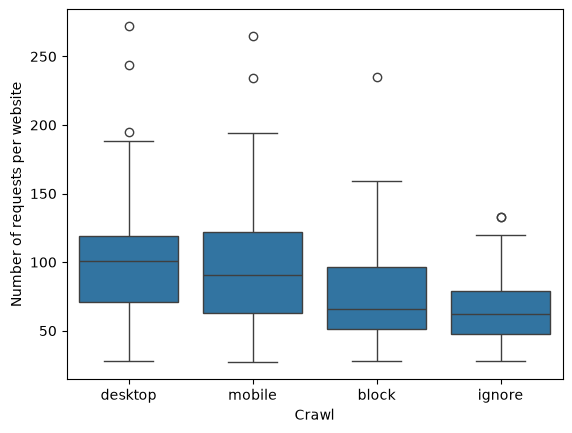

In [163]:
sns.boxplot(df, x="mode", y="num_requests")
plt.xlabel("Crawl")
plt.ylabel("Number of requests per website")
plt.show()

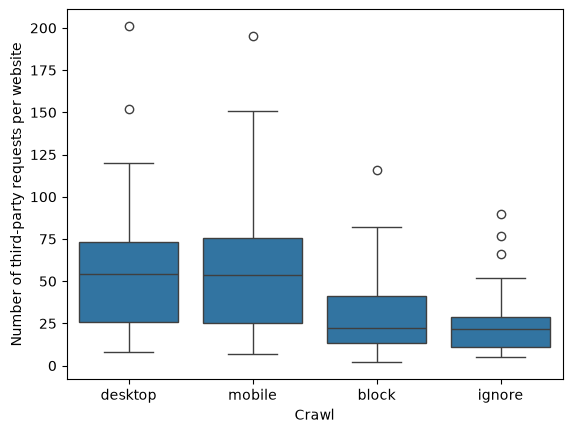

In [164]:
sns.boxplot(df, x="mode", y="num_third_party_requests")
plt.xlabel("Crawl")
plt.ylabel("Number of third-party requests per website")
plt.show()

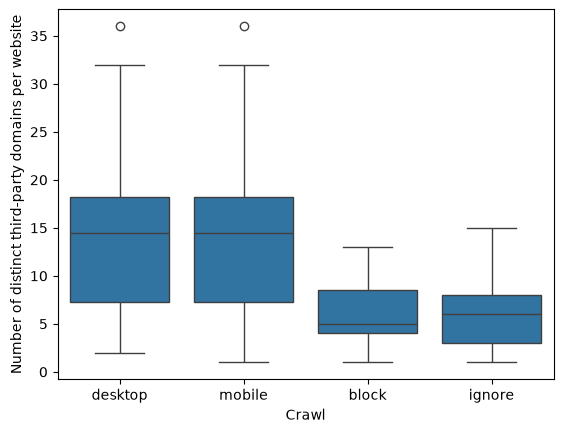

In [165]:
sns.boxplot(df, x="mode", y="num_dist_third_party_domains")
plt.xlabel("Crawl")
plt.ylabel("Number of distinct third-party domains per website")
plt.show()

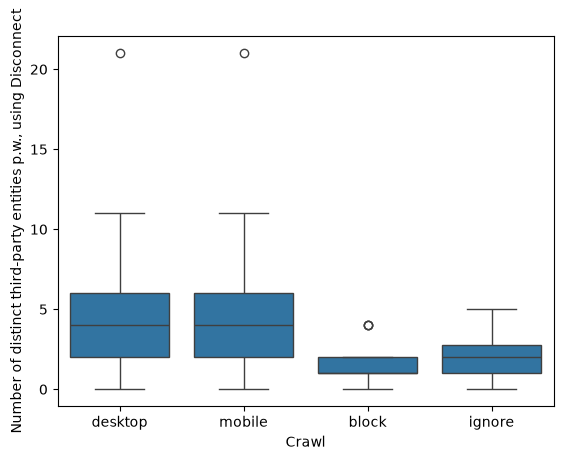

In [166]:
sns.boxplot(df, x="mode", y="num_dist_third_party_entites_per_website")
plt.xlabel("Crawl")
plt.ylabel("Number of distinct third-party entities p.w., using Disconnect")
plt.show()

Create Table to compare data from 1a - 1d

In [167]:
metrics = ["num_requests", "num_third_party_requests", "num_dist_third_party_domains", "num_dist_third_party_entites_per_website"]
table = df.groupby("mode")[metrics].agg(["min", "median", "max"]).T.unstack()
table

mode                                     block               desktop         \
                                           min median    max     min median   
num_requests                              28.0   66.0  235.0    28.0  101.0   
num_third_party_requests                   2.0   22.0  116.0     8.0   54.5   
num_dist_third_party_domains               1.0    5.0   13.0     2.0   14.5   
num_dist_third_party_entites_per_website   0.0    1.0    4.0     0.0    4.0   

mode                                            ignore               mobile  \
                                            max    min median    max    min   
num_requests                              272.0   28.0   62.0  133.0   27.0   
num_third_party_requests                  201.0    5.0   21.5   90.0    7.0   
num_dist_third_party_domains               36.0    1.0    6.0   15.0    1.0   
num_dist_third_party_entites_per_website   21.0    0.0    2.0    5.0    0.0   

mode                                                    
                                         median    max  
num_requests                               90.5  265.0  
num_third_party_requests                   53.5  195.0  
num_dist_third_party_domains               14.5   36.0  
num_dist_third_party_entites_per_website    4.0   21.0

Barplot for 3 a,b

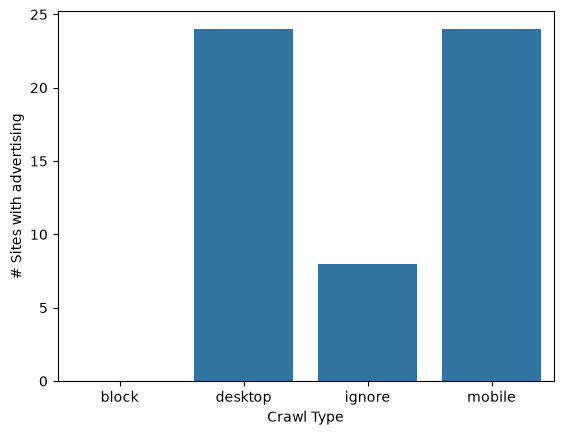

In [168]:
advertising_counts = df.groupby("mode")["contacts_advertising"].sum().reset_index()
sns.barplot(advertising_counts, x="mode", y="contacts_advertising")
plt.xlabel("Crawl Type")
plt.ylabel("# Sites with advertising")
plt.show()

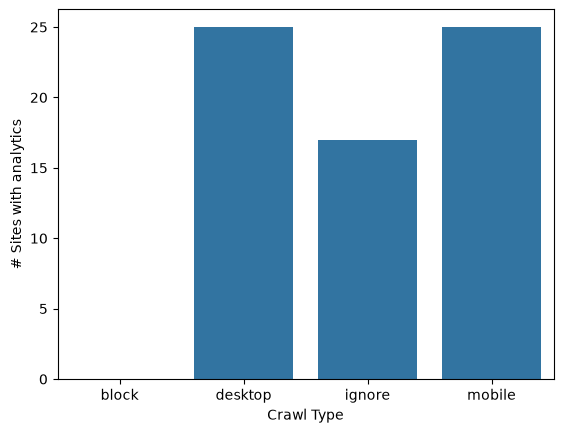

In [169]:
analytics_counts = df.groupby("mode")["contacts_analytics"].sum().reset_index()
sns.barplot(analytics_counts, x="mode", y="contacts_analytics")
plt.xlabel("Crawl Type")
plt.ylabel("# Sites with analytics")
plt.show()

Analysis for 4

In [170]:
country_table = df[df["mode"]=="desktop"].groupby("country")[metrics].agg(["min", "median", "max"]).T.unstack()
country_table

country                                     nl                  uk         \
                                           min median    max   min median   
num_requests                              28.0   69.0  272.0  85.0  143.5   
num_third_party_requests                   9.0   37.5   74.0  50.0  105.0   
num_dist_third_party_domains               3.0   10.5   19.0  15.0   22.0   
num_dist_third_party_entites_per_website   1.0    4.5    8.0   2.0    7.5   

country                                            us                
                                            max   min median    max  
num_requests                              244.0  28.0   82.5  120.0  
num_third_party_requests                  201.0   8.0   27.0   77.0  
num_dist_third_party_domains               36.0   2.0    8.5   15.0  
num_dist_third_party_entites_per_website   21.0   0.0    2.0    5.0

Analysis for 5

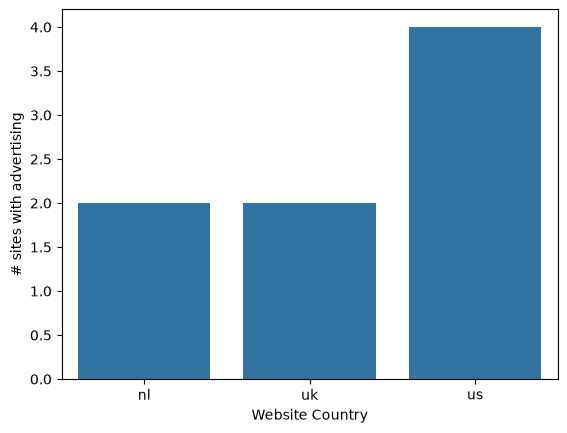

In [171]:
ignore_adveritising_counts = df[df["mode"]=="ignore"].groupby("country")["contacts_advertising"].sum().reset_index()

sns.barplot(ignore_adveritising_counts, x="country", y="contacts_advertising")
plt.xlabel("Website Country")
plt.ylabel("# sites with advertising")
plt.show()



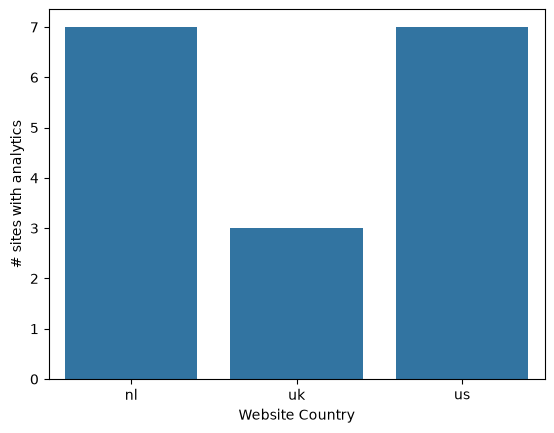

In [172]:
ignore_analytics_counts = df[df["mode"]=="ignore"].groupby("country")["contacts_analytics"].sum().reset_index()

sns.barplot(ignore_analytics_counts, x="country", y="contacts_analytics")
plt.xlabel("Website Country")
plt.ylabel("# sites with analytics")
plt.show()


Prep for 6 and 7

In [173]:
# Dictionary to map the set of websites that contacted every third-party domain in both the desktop and mobile crawl
domains_per_site = {}

for crawl in hars:
    domains_per_site[crawl] = {}
    for site, har in hars[crawl].items():
        page_url = get_page_url(har)
        valid_entries = get_valid_entries(har)

        # Iterate through all domains from the set of third-party domains
        for domain in get_third_party_domains(valid_entries, page_url):
            if domain not in domains_per_site[crawl]:                                   # If the domain is not in domains_per_site, we add it
                domains_per_site[crawl][domain] = set()
            
            domains_per_site[crawl][domain].add(site)

Analysis for 6

In [174]:
only_desktop = set(domains_per_site["desktop"]) - set(domains_per_site["mobile"])       # 6.a) The domains that are unique to the desktop crawl
only_mobile = set(domains_per_site["mobile"]) - set(domains_per_site["desktop"])        # 6.b) The domains that are unique to the mobile crawl

# A function to get the n most prevalent third-party domains
def rank_domains(crawl, unique_domains, top_n=3):
    pairs = []                                                                          # List of (top_u=3mber of websites, domain) pairs

    for domain in unique_domains:
        contacted_set = domains_per_site[crawl][domain]                                 # Websites that contacted the domain
        pairs.append((len(contacted_set), domain))
    
    # Sorted by the website count with the largest first
    pairs.sort(reverse=True)
    
    table = pd.DataFrame(pairs[:top_n], columns=["Site count", "Domain"])               # Keeps only the n domains

    return table[["Domain", "Site count"]]

table_6a = rank_domains("desktop", only_desktop)                                        # Domains contacted uniquely in the Desktop crawl
table_6b = rank_domains("mobile", only_mobile)                                          # Domains contacted uniquely in the Mobile crawl

# Puts both table 6a and 6b together as well as the headers stated in the assignment
table_6 = pd.concat([table_6a, table_6b], axis=1, keys=["Domains observed in Crawl-Desktop", "Domains observed in Crawl-Mobile"])

table_6 = table_6.reindex(range(3)).fillna("-")
table_6.index = [1, 2, 3]

table_6

Domains observed in Crawl-Desktop             \
                             Domain Site count   
1                                 -          -   
2                                 -          -   
3                                 -          -   

  Domains observed in Crawl-Mobile             
                            Domain Site count  
1                                -          -  
2                                -          -  
3                                -          -

Analysis for 7

In [175]:
# Builds a table of the top 10 most prevalent third-party domains based on the number of distinct websites 
# where a third-party domain was contacted
def top_domains_table(crawl, top_n=10):
    pairs = []                                                                          # List of (number of websites, domain) pairs

    # sites: set of websites that contacted the domain
    for domain, sites in domains_per_site[crawl].items():
        distinct_websites = len(sites)
        pairs.append((distinct_websites, domain))
    
    # Sorted by the website count with the largest first
    pairs.sort(reverse=True)

    rows = []                                                                           # One row per domain: (domain, website count, categories)
    for num_sites, domain in pairs[:top_n]:                                             # Iterate up until the 10th most prevalent domain
        categories = domain_to_categories.get(domain, set())                            # Retrieves the categories of this domain in Disconnect's blocklist
        
        if categories:
            cat_text = ", ".join(sorted(categories))                                    # List of categories
        else:
            cat_text = "NA"                                                             # For cases where the domain is not in Disconnect's list
        
        rows.append((domain, num_sites, cat_text))
    
    # Makes the list of rows into a table of columns found in the assignment
    table = pd.DataFrame(rows, columns=["Third-party domain", "Number of distinct websites", "Disconnect categories"])
    table.index = range(1, len(table) + 1)                                              # Lists the table from 1-10 instead of 0-9
    return table

# Creates one table per crawl
for crawl in ["desktop", "mobile", "block", "ignore"]:
    print(crawl.capitalize(), "crawl")
    display(top_domains_table(crawl))


Desktop crawl


,Third-party domain,Number of distinct websites,Disconnect categories
1,googletagmanager.com,28,NA
2,google.com,22,Content
3,doubleclick.net,22,"Advertising, Email, FingerprintingGeneral"
4,google.nl,21,Content
5,google-analytics.com,16,"Analytics, Email, FingerprintingGeneral"
6,facebook.net,14,"FingerprintingGeneral, Social"
7,facebook.com,14,"FingerprintingGeneral, Social"
8,linkedin.com,13,Social
9,licdn.com,13,Social
10,siteimproveanalytics.io,9,Analytics


Mobile crawl


,Third-party domain,Number of distinct websites,Disconnect categories
1,googletagmanager.com,27,NA
2,google.com,22,Content
3,doubleclick.net,22,"Advertising, Email, FingerprintingGeneral"
4,google.nl,21,Content
5,google-analytics.com,16,"Analytics, Email, FingerprintingGeneral"
6,facebook.net,14,"FingerprintingGeneral, Social"
7,facebook.com,14,"FingerprintingGeneral, Social"
8,linkedin.com,13,Social
9,licdn.com,13,Social
10,siteimproveanalytics.io,9,Analytics


Block crawl


,Third-party domain,Number of distinct websites,Disconnect categories
1,googletagmanager.com,28,NA
2,google.nl,18,Content
3,gstatic.com,9,Content
4,google.com,8,Content
5,fonts.googleapis.com,8,NA
6,youtube.com,7,Content
7,cloudflare.com,6,Content
8,ytimg.com,5,Content
9,onetrust.com,5,ConsentManagers
10,typekit.net,4,NA


Ignore crawl


,Third-party domain,Number of distinct websites,Disconnect categories
1,googletagmanager.com,23,NA
2,google-analytics.com,11,"Analytics, Email, FingerprintingGeneral"
3,gstatic.com,8,Content
4,google.com,7,Content
5,fonts.googleapis.com,7,NA
6,cloudflare.com,6,Content
7,youtube.com,5,Content
8,siteimproveanalytics.io,5,Analytics
9,siteimproveanalytics.com,5,Analytics
10,doubleclick.net,5,"Advertising, Email, FingerprintingGeneral"


Prep for 8

In [176]:
desktop = df[df["mode"] == "desktop"]                                                       # Gets the rows from the desktop crawl

# Websites with the highest number of distinct third-party domains, sorting from largest to smallest, taking the top 3
highest = desktop.sort_values("num_dist_third_party_domains", ascending=False).head(3)

# Websites witht the lowest number of distinct third-party domains, sorting from smallest to largest, taking the first 3
lowest = desktop.sort_values("num_dist_third_party_domains", ascending=True).head(3)

# Showing a table with the headers needed (website, country, number of domains) for both cases
highest[["site", "country", "num_dist_third_party_domains"]], lowest[["site", "country", "num_dist_third_party_domains"]]

(                site country  num_dist_third_party_domains
 25  nottingham.ac.uk      uk                            36
 8        leeds.ac.uk      uk                            32
 20  manchester.ac.uk      uk                            31,
           site country  num_dist_third_party_domains
 28     mit.edu      us                             2
 5       rug.nl      nl                             3
 3   utwente.nl      nl                             4)

Analysis for 8

In [177]:
# Tranco ranks from https://tranco-list.eu/query for the top 3 highest and top 3 lowest sites with distinct third-party domains
# Tranco ranks retrieved on 10 November 2026
tranco_ranks = {
    "nottingham.ac.uk": 8540,
    "leeds.ac.uk": 5952,
    "manchester.ac.uk": 4951,
    "mit.edu": 238,
    "rug.nl": 5587,
    "utwente.nl": 6529
}

# Builds a table for the 3 highest or 3 lowest websites
def rank_table(table):
    rows = []                                                                       # One row per website: (website, rank, country, number of domains)

    for _, row in table.iterrows():                                                 # iterrows() gives a pair (index, row), where index is not needed for the function
        rows.append((row["site"],                                                   # The university website
                    tranco_ranks[row["site"]],                                      # The rank found in the tranco_ranks dictionary
                    row["country"].upper(),                                         # The country the website belongs to
                    int(row["num_dist_third_party_domains"])))                      # The number of distinct third-party domains, using a whole number instead of a float
    
    # Creates a table from the list of rows
    return pd.DataFrame(rows, columns=["Website", "Tranco rank", "Country", "Number of distinct third-party domains"])

table_8a = rank_table(highest)
table_8a.index = [1, 2, 3]                                                          # Index 1-3 instead of 0-2
table_8b = rank_table(lowest)
table_8b.index = [1, 2, 3]                                                          # Index 1-3 instead of 0-2

display(table_8a)
display(table_8b)

,Website,Tranco rank,Country,Number of distinct third-party domains
1,nottingham.ac.uk,8540,UK,36
2,leeds.ac.uk,5952,UK,32
3,manchester.ac.uk,4951,UK,31


,Website,Tranco rank,Country,Number of distinct third-party domains
1,mit.edu,238,US,2
2,rug.nl,5587,NL,3
3,utwente.nl,6529,NL,4


Analysis for 9

In [178]:
domain_to_categories = {}                                                                       # The domain and the set of categories from Disconnect's blocklist
session_replay_domains = set()                                                                  # A set with all domains marked as a session replay

for category, entity_list in services["categories"].items():
    for entity_dict in entity_list:
        for entity_name, entity_info in entity_dict.items():
            is_session_replay = str(entity_info.get("session-replay", "")).lower() == "true"    # Checks if the website is marked as a session replay by Disconnect

            for key, value in entity_info.items():
                if isinstance(value, list):                                                     # Domains are found in a list, so this only gets the values that contain domains

                    for domain in value:
                        domain_to_categories.setdefault(domain, set()).add(category)            # Adds the domain to domain_to_categories together with its Disconnect categories

                        if is_session_replay:                                                   # If the company is a session-replay company, add it to the session_replay_domains set
                            session_replay_domains.add(domain)

# A function that checks if a URL belongs to a session-replay domain and which one
def get_session_replay_domain(request_url):
    hostname = urlparse(request_url).hostname

    if hostname is None:
        return None
    
    parts = hostname.split(".")
    
    # Tests all parts of the hostname to see any indication of a session-replay domain, shortening 
    # the hostname with one part for every iteration
    for i in range(len(parts) - 1):
        candidate = ".".join(parts[i:])

        if candidate in session_replay_domains:
            return candidate
    
    return None

# Keeps which session-replay domain each website had contacted, as well as in which crawl
# found = {
#     (website, session_replay_domain): {crawl_mode_1, crawl_mode_2, ...}
# }
found = {}

for crawl in ["desktop", "mobile", "block", "ignore"]:
    for site, har in hars[crawl].items():
        for entry in get_valid_entries(har):
            # Checks which session-replay domain the request went to (if applicable) for every valid entry
            replay_domain = get_session_replay_domain(entry["request"]["url"])

            if replay_domain is not None:                                                       # Only takes cases with session-replay domains
                key = (site, replay_domain)

                if key not in found:
                    found[key] = set()                                                          # If this is the first instance of the site and its session-replay domain, create a new set
                
                found[key].add(crawl)                                                           # Add the crawl mode in the found dictionary

# A list of rows: (website, session-replay domain, country, crawl modes)
rows_9 = []

# The key in found is (site, replay_domain) and the crawl modes as its values
for (site, replay_domain), crawls in found.items():
    crawl_names = []

    for crawl in ["desktop", "mobile", "block", "ignore"]:
        if crawl in crawls:                                                                     # If the crawl mode is found as an observed crawl
            crawl_names.append(crawl.capitalize())                                              # Add it to the crawl names for the site
    
    rows_9.append((site, replay_domain, domain_to_country[site].upper(), ", ".join(crawl_names)))

# Sorts the list in alphabetical order
rows_9.sort()

# Turns a list of rows into a table
table_9 = pd.DataFrame(rows_9, columns=["Website", "Session replay domain", "Country", "Observed crawl(s)"])
# Changes the starting index from 0 to 1
table_9.index = range(1, len(table_9) + 1)

table_9


,Website,Session replay domain,Country,Observed crawl(s)
1,lse.ac.uk,hotjar.com,UK,"Desktop, Mobile"
2,lse.ac.uk,hotjar.io,UK,"Desktop, Mobile"
3,manchester.ac.uk,hotjar.com,UK,"Desktop, Mobile"
4,stanford.edu,contentsquare.net,US,"Desktop, Mobile, Ignore"
5,uchicago.edu,hotjar.com,US,"Desktop, Mobile, Ignore"
6,uchicago.edu,hotjar.io,US,Mobile
7,warwick.ac.uk,hotjar.com,UK,"Desktop, Mobile"
